In [ ]:
from google.colab import userdata
import sys, os, subprocess

TOKEN = userdata.get('GITHUB_TOKEN')
USERNAME = "vedika0806"
REPO = "data266-5937"
HW = "hw4"

os.system(f"git clone https://{TOKEN}@github.com/{USERNAME}/{REPO}.git /content/{REPO}")

sys.path.append(f"/content/{REPO}/common")
import colab_bootstrap, importlib
importlib.reload(colab_bootstrap)
from colab_bootstrap import setup_repo, get_logger, git_commit_push, git_tag_push

REPO_PATH = f"/content/{REPO}"
HW_PATH = setup_repo(HW, USERNAME, REPO, TOKEN)
logger = get_logger(HW_PATH)

logger.info(f"=== Session started for {HW} ===")
git_commit_push(REPO_PATH, f"{HW}: session start")

INFO:/content/data266-5937/hw4:=== Session started for hw4 ===


Working directory: /content/data266-5937/hw4
[main 2470bd2] hw4: session start
 1 file changed, 6 insertions(+)
 


In [ ]:
SID4 = 5937
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")
logger.info(f"Params: SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")

INFO:/content/data266-5937/hw4:Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


# **Part 1 – Data Preparation**

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np, random, math, time
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
logger.info(f"Imports done, seed={SEED}, device={device}")

INFO:/content/data266-5937/hw4:Imports done, seed=5937, device=cuda


Device: cuda


In [ ]:
DATA_PATH = f"{HW_PATH}/Shakespeare.txt"
if not os.path.exists(DATA_PATH):
    from google.colab import files
    up = files.upload()
    fname = list(up.keys())[0]
    os.replace(fname, DATA_PATH)

with open(DATA_PATH, "r", encoding="utf-8") as f:
    text = f.read()

print("Characters:", len(text))
print(text[:200])
logger.info(f"Loaded Shakespeare.txt ({len(text)} chars)")
git_commit_push(REPO_PATH, f"{HW}: add Shakespeare.txt dataset")

INFO:/content/data266-5937/hw4:Loaded Shakespeare.txt (1738 chars)


Saving shakespeare.txt to shakespeare.txt
Characters: 1738
ROMEO:
But, soft! what light through yonder window breaks?
It is the east, and Juliet is the sun.
Arise, fair sun, and kill the envious moon,
Who is already sick and pale with grief,
That thou her mai
[main 72a7f5c] hw4: add Shakespeare.txt dataset
 2 files changed, 61 insertions(+)
 create mode 100644 hw4/Shakespeare.txt
 


In [ ]:
chars = sorted(set(text))
char_to_idx = {ch: i for i, ch in enumerate(chars)}
idx_to_char = {i: ch for ch, i in char_to_idx.items()}
vocab_size = len(chars)

encode = lambda s: [char_to_idx[c] for c in s]
decode = lambda ids: "".join(idx_to_char[int(i)] for i in ids)

print("Vocabulary size:", vocab_size)
print("Vocab:", repr("".join(chars)))

data = torch.tensor(encode(text), dtype=torch.long)
print("Encoded tensor shape:", data.shape)
logger.info(f"Tokenization done: vocab_size={vocab_size}, total_tokens={len(data)}")

INFO:/content/data266-5937/hw4:Tokenization done: vocab_size=49, total_tokens=1738


Vocabulary size: 49
Vocab: '\n !,.:;?ABCDEHIJLMNORSTUWabcdefghiklmnoprstuvwyz’'
Encoded tensor shape: torch.Size([1738])


In [ ]:
SEQ_LEN = 128
STRIDE = 1
class CharDataset(Dataset):
    def __init__(self, data, seq_len, stride):
        self.data, self.seq_len = data, seq_len
        self.starts = list(range(0, len(data) - seq_len - 1, stride))
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, i):
        t = self.starts[i]
        x = self.data[t : t + self.seq_len]            # tokens t .. t+127
        y = self.data[t + 1 : t + self.seq_len + 1]    # tokens t+1 .. t+128
        return x, y

dataset = CharDataset(data, SEQ_LEN, STRIDE)
print("Number of windows:", len(dataset))

for k, idx in enumerate([0, len(dataset) - 1], start=1):
    x, y = dataset[idx]
    print(f"\n--- Example {k} (window {idx}) ---")
    print("INPUT :", repr(decode(x)))
    print("TARGET:", repr(decode(y)))

logger.info(f"Sliding window dataset built: seq_len={SEQ_LEN}, stride={STRIDE}, windows={len(dataset)}")
git_commit_push(REPO_PATH, f"{HW}: part 1 tokenization + sliding window dataset")

INFO:/content/data266-5937/hw4:Sliding window dataset built: seq_len=128, stride=1, windows=1609


Number of windows: 1609

--- Example 1 (window 0) ---
INPUT : 'ROMEO:\nBut, soft! what light through yonder window breaks?\nIt is the east, and Juliet is the sun.\nArise, fair sun, and kill the '
TARGET: 'OMEO:\nBut, soft! what light through yonder window breaks?\nIt is the east, and Juliet is the sun.\nArise, fair sun, and kill the e'

--- Example 2 (window 1608) ---
INPUT : 'hee who I am:\nMy name, dear saint, is hateful to myself,\nBecause it is an enemy to thee;\nHad I it written, I would tear the word'
TARGET: 'ee who I am:\nMy name, dear saint, is hateful to myself,\nBecause it is an enemy to thee;\nHad I it written, I would tear the word.'
[main 86014ce] hw4: part 1 tokenization + sliding window dataset
 1 file changed, 6 insertions(+)
 


# **Part 2 – GPT Architecture**

In [ ]:
class MultiHeadCausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, block_size, dropout=0.0):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)
        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)
        # causal mask: 1 = allowed, 0 = future (blocked)
        mask = torch.tril(torch.ones(block_size, block_size)).view(1, 1, block_size, block_size)
        self.register_buffer("mask", mask)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        # (B, T, C) -> (B, n_heads, T, head_dim)
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)   # (B, h, T, T)
        scores = scores.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        weights = self.attn_drop(F.softmax(scores, dim=-1))

        out = weights @ v                                   # (B, h, T, head_dim)
        out = out.transpose(1, 2).contiguous().view(B, T, C)  # concat heads
        return self.resid_drop(self.proj(out))

logger.info("Defined MultiHeadCausalSelfAttention")

INFO:/content/data266-5937/hw4:Defined MultiHeadCausalSelfAttention


In [ ]:
class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, block_size, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadCausalSelfAttention(d_model, n_heads, block_size, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model),
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # pre-norm, matches demo
        x = x + self.ff(self.ln2(x))
        return x

logger.info("Defined DecoderBlock")

INFO:/content/data266-5937/hw4:Defined DecoderBlock


In [ ]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_layers, block_size, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)
        self.blocks = nn.ModuleList(
            [DecoderBlock(d_model, n_heads, block_size, dropout) for _ in range(n_layers)]
        )
        self.ln_f = nn.LayerNorm(d_model)          # final norm, matches demo's self.ln
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.token_emb(idx) + self.pos_emb(pos)
        for blk in self.blocks:
            x = blk(x)
        x = self.ln_f(x)                            # apply before head
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

D_MODEL, N_HEADS, N_LAYERS = 128, 4, 2

model = MiniGPT(vocab_size, D_MODEL, N_HEADS, N_LAYERS, SEQ_LEN).to(device)
n_params = sum(p.numel() for p in model.parameters())

print(f"Total parameters : {n_params:,}")
print(f"Hidden dimension : {D_MODEL}")
print(f"Number of heads  : {N_HEADS}")
print(f"Number of layers : {N_LAYERS}")
logger.info(f"Model built: params={n_params}, d_model={D_MODEL}, heads={N_HEADS}, layers={N_LAYERS}")
git_commit_push(REPO_PATH, f"{HW}: part 2 GPT architecture (MHA, decoder block, model)")

INFO:/content/data266-5937/hw4:Model built: params=425777, d_model=128, heads=4, layers=2


Total parameters : 425,777
Hidden dimension : 128
Number of heads  : 4
Number of layers : 2
[main dfe44cc] hw4: part 2 GPT architecture (MHA, decoder block, model)
 1 file changed, 3 insertions(+)
 


In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np, random, math, time
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
logger.info(f"Imports done, seed={SEED}, device={device}")

# 1) Output shape
xb, yb = next(iter(DataLoader(dataset, batch_size=4)))
logits, loss = model(xb.to(device), yb.to(device))
print("logits:", logits.shape, "| initial loss:", loss.item(), "| ln(vocab) =", math.log(vocab_size))

# 2) Causality test: changing a FUTURE token must not change earlier outputs
model.eval()
x1 = xb[:1].to(device).clone()
x2 = x1.clone(); x2[0, SEQ_LEN // 2] = (x2[0, SEQ_LEN // 2] + 1) % vocab_size
with torch.no_grad():
    l1, _ = model(x1); l2, _ = model(x2)
print(f"Positions <{SEQ_LEN // 2} unchanged:", torch.allclose(l1[0, :SEQ_LEN // 2], l2[0, :SEQ_LEN // 2], atol=1e-5))
print(f"Position {SEQ_LEN // 2}+ changed   :", not torch.allclose(l1[0, SEQ_LEN // 2:], l2[0, SEQ_LEN // 2:], atol=1e-5))
model.train()
logger.info("Sanity checks passed (shape + causal mask)")

INFO:/content/data266-5937/hw4:Imports done, seed=5937, device=cuda
INFO:/content/data266-5937/hw4:Sanity checks passed (shape + causal mask)


Device: cuda
logits: torch.Size([4, 128, 49]) | initial loss: 3.982240915298462 | ln(vocab) = 3.8918202981106265
Positions <64 unchanged: True
Position 64+ changed   : True


# **Part 3 – Training**

In [ ]:
EPOCHS = 8
BATCH_SIZE = 32
LR = 4e-4

loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

epoch_losses = []
logger.info(f"Training start: epochs={EPOCHS}, batch={BATCH_SIZE}, lr={LR}, optimizer=Adam")

for epoch in range(1, EPOCHS + 1):
    model.train()
    total, n, t0 = 0.0, 0, time.time()
    for step, (xb, yb) in enumerate(loader):
        xb, yb = xb.to(device), yb.to(device)
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total += loss.item(); n += 1
        if step % 500 == 0:
            print(f"  epoch {epoch} step {step}/{len(loader)} loss {loss.item():.4f}")
    avg = total / n
    epoch_losses.append(avg)
    msg = f"Epoch {epoch}/{EPOCHS} | train loss {avg:.4f} | {time.time()-t0:.0f}s"
    print(msg)
    logger.info(msg)
    git_commit_push(REPO_PATH, f"{HW}: finished epoch {epoch}, loss {avg:.4f}")

INFO:/content/data266-5937/hw4:Training start: epochs=8, batch=32, lr=0.0004, optimizer=Adam


  epoch 1 step 0/50 loss 4.0234


INFO:/content/data266-5937/hw4:Epoch 1/8 | train loss 2.9987 | 0s


Epoch 1/8 | train loss 2.9987 | 0s
[main 7401540] hw4: finished epoch 1, loss 2.9987
 1 file changed, 4 insertions(+)
 
  epoch 2 step 0/50 loss 2.5315


INFO:/content/data266-5937/hw4:Epoch 2/8 | train loss 2.3795 | 0s


...

Epoch 6/8 | train loss 1.9569 | 0s
[main d91e82d] hw4: finished epoch 6, loss 1.9569
 1 file changed, 1 insertion(+)
 
  epoch 7 step 0/50 loss 1.9280


INFO:/content/data266-5937/hw4:Epoch 7/8 | train loss 1.8471 | 0s


Epoch 7/8 | train loss 1.8471 | 0s
[main cd797d4] hw4: finished epoch 7, loss 1.8471
 1 file changed, 1 insertion(+)
 
  epoch 8 step 0/50 loss 1.8326


INFO:/content/data266-5937/hw4:Epoch 8/8 | train loss 1.7114 | 0s


Epoch 8/8 | train loss 1.7114 | 0s
[main 73af4c2] hw4: finished epoch 8, loss 1.7114
 1 file changed, 1 insertion(+)
 


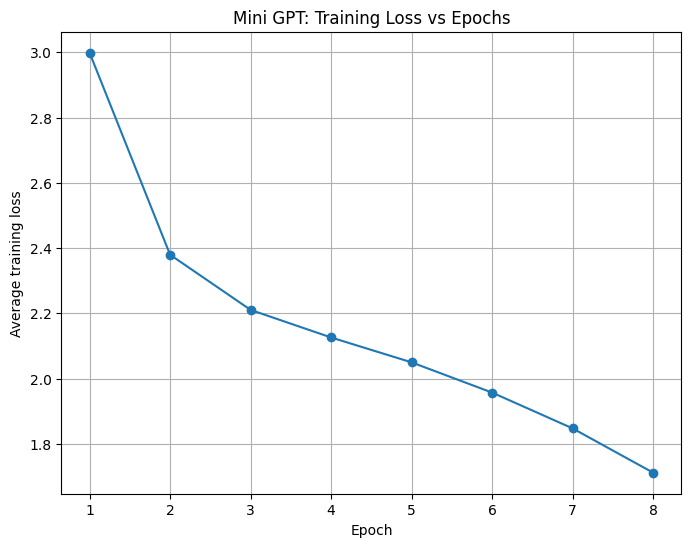

INFO:/content/data266-5937/hw4:Saved training_loss_curve.png


50050 bytes
[main 64b69cc] hw4: part 3 training loss curve
 2 files changed, 1 insertion(+)
 


In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(range(1, EPOCHS + 1), epoch_losses, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Average training loss")
plt.title("Mini GPT: Training Loss vs Epochs")
plt.grid(True)
plt.savefig(f"{HW_PATH}/training_loss_curve.png", bbox_inches="tight", dpi=150)  # BEFORE show()
plt.show()
plt.close()

print(os.path.getsize(f"{HW_PATH}/training_loss_curve.png"), "bytes")
logger.info("Saved training_loss_curve.png")
git_commit_push(REPO_PATH, f"{HW}: part 3 training loss curve")

In [ ]:
@torch.no_grad()
def generate(model, prompt, max_new_tokens=300, mode="greedy", temperature=1.0, top_k=None, seed=SEED):
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)   # reproducible sampling
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -model.block_size:]               # crop to context window
        logits, _ = model(idx_cond)
        logits = logits[:, -1, :]                           # last position only

        if mode == "greedy":
            next_id = torch.argmax(logits, dim=-1, keepdim=True)
        else:
            logits = logits / temperature
            if mode == "topk":
                v, _ = torch.topk(logits, top_k)
                logits = logits.masked_fill(logits < v[:, [-1]], float("-inf"))
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, 1, generator=g)
        idx = torch.cat([idx, next_id], dim=1)
    return decode(idx[0].tolist())

logger.info("Defined generate() with greedy / temperature / top-k")

INFO:/content/data266-5937/hw4:Defined generate() with greedy / temperature / top-k


# **Part 4 – Sampling**

In [ ]:
PROMPT = "ROMEO:"
samples = {}

samples["greedy"] = generate(model, PROMPT, mode="greedy")
print("=== GREEDY ===\n", samples["greedy"])
logger.info("Generated greedy sample")

INFO:/content/data266-5937/hw4:Generated greedy sample


=== GREEDY ===
 ROMEO:
I the theat the she shye sell akspeak the spe she spe speakspe speyeneng:
I at ake ake aks akse aks aks aks aks akspe aks the akitit tin t t akine sphe in sphe sphen spheakin sphen iouticakin se the t se s thererin.
Herererisereseakiousenvinvious ses sese s; th s s illllll t thereak theane thererer


In [ ]:
for T in [0.3, 0.8, 1.5]:
    key = f"temperature_{T}"
    samples[key] = generate(model, PROMPT, mode="temperature", temperature=T)
    print(f"\n=== TEMPERATURE {T} ===\n{samples[key]}")
    logger.info(f"Generated temperature={T} sample")

INFO:/content/data266-5937/hw4:Generated temperature=0.3 sample



=== TEMPERATURE 0.3 ===
ROMEO:
Shy not nor Ror Rome, nome, beome noname?
Tor nameor nar theor nor nameoor n whell ameeor theor n


ROMEOMEO:
Sor theameameamee, t thame at t thathathat whe t whathat whe or whe thee whe whor whe whicare s?
Hellllllll se weall were butitheat me t atis;










Roul I I atomeneto.
Ro, tomeomeomeom


INFO:/content/data266-5937/hw4:Generated temperature=0.8 sample



=== TEMPERATURE 0.8 ===
ROMEO:
Shy d:
I in, mor thy my now My fove, sove,
Jut, swe.
Ore!
I’lll me
Reme Rome befome Ro,
What nate thy that de ar d:
Bewhalhar hand t is rdonthou what ho wor than, I’dornoul hedo t ne.
Be t o the?
Ano cr no ananame tin.
I r beame;
Beor or inord wor ad, tofoo and wonor tor ainor st nd door and fot he


INFO:/content/data266-5937/hw4:Generated temperature=1.5 sample



=== TEMPERATURE 1.5 ===
ROMEO:
Sh sre wokn, mee
Tho! thongue, fo UEThovearJULTwhe spargharilfor,Wh eme fat n, Wle thhe
Datho ngue I sitwe d warid hy bew hore.

Whves nvinotno? atato nd beMouave I’irenR;’d;
ze! Ron.
BeAndon, t? f ifor baverd ama tin lir c, ame;
Whortom: acede teaicr gTfecame, me ha for ainvindCand d or ard foomfh


In [ ]:
for k in [3, 40]:
    key = f"topk_{k}"
    samples[key] = generate(model, PROMPT, mode="topk", top_k=k, temperature=1.0)
    print(f"\n=== TOP-K (k={k}) ===\n{samples[key]}")
    logger.info(f"Generated top-k k={k} sample")

INFO:/content/data266-5937/hw4:Generated top-k k=3 sample



=== TOP-K (k=3) ===
ROMEO:
Shys the nout no thy name, she sper shous:
Hat namerer thyenamend send sphendo wis thes
Ther spall tis



Itatatather takllll akeret s t meatather se tise speathe tisers tis s s then.








JULIEThys aknourenaknothy my athermend thy thy thellf, athelf.
Anamelf.


ROr that thathe t t wheame whou w


INFO:/content/data266-5937/hw4:Generated top-k k=40 sample



=== TOP-K (k=40) ===
ROMEO:
Shys the?
Why no thy mernow My foname, whar ar whe
Tar gharilfor be.
I athamy, tle.
Ahe
Dathy nanothy that d we
Ar ny be! har hamefvefovearsthe?
Nouth nd be.
Tand I’d, noullfoze than.

Be dor he? t icar thar anama tin.
ROr beame;
Whor om:
Wigu womar mellf, tand t’lll t be, nvind f.
’d ore?
Hef, my 


In [ ]:
with open(f"{HW_PATH}/generated_samples.txt", "w") as f:
    for name, s in samples.items():
        f.write(f"===== {name} =====\n{s}\n\n")

logger.info("Saved generated_samples.txt")
git_commit_push(REPO_PATH, f"{HW}: part 4 sampling outputs (greedy, temperature, top-k)")

INFO:/content/data266-5937/hw4:Saved generated_samples.txt


[main 340fd3e] hw4: part 4 sampling outputs (greedy, temperature, top-k)
 2 files changed, 86 insertions(+), 36 deletions(-)
 


In [ ]:
def distinct_ratio(s):   # unique words / total words
    w = s.split()
    return len(set(w)) / max(len(w), 1)

def valid_word_ratio(s):  # fraction of words that appear in the training text
    vocab_words = set(text.split())
    w = s.split()
    return sum(x in vocab_words for x in w) / max(len(w), 1)

print(f"{'method':<18}{'distinct-word ratio':>22}{'real-word ratio':>18}")
for name, s in samples.items():
    print(f"{name:<18}{distinct_ratio(s):>22.3f}{valid_word_ratio(s):>18.3f}")

method               distinct-word ratio   real-word ratio
greedy                             0.638             0.207
temperature_0.3                    0.796             0.204
temperature_0.8                    0.899             0.261
temperature_1.5                    0.981             0.093
topk_3                             0.863             0.196
topk_40                            0.967             0.148


In [76]:
print("vocab_size:", vocab_size)
print("total params:", sum(p.numel() for p in model.parameters()))
print("epoch_losses:", epoch_losses)
print()
print("=== GREEDY ===")
print(samples["greedy"])
print()
print("=== TOP-K 3 ===")
print(samples["topk_3"])
print()
print("=== TOP-K 40 ===")
print(samples["topk_40"])

vocab_size: 49
total params: 425777
epoch_losses: [2.998704261779785, 2.3794915151596068, 2.2103991746902465, 2.125871524810791, 2.049596757888794, 1.956890742778778, 1.8471203470230102, 1.7113662791252136]

=== GREEDY ===
ROMEO:
I the theat the she shye sell akspeak the spe she spe speakspe speyeneng:
I at ake ake aks akse aks aks aks aks akspe aks the akitit tin t t akine sphe in sphe sphen spheakin sphen iouticakin se the t se s thererin.
Herererisereseakiousenvinvious ses sese s; th s s illllll t thereak theane thererer

=== TOP-K 3 ===
ROMEO:
Shys the nout no thy name, she sper shous:
Hat namerer thyenamend send sphendo wis thes
Ther spall tis



Itatatather takllll akeret s t meatather se tise speathe tisers tis s s then.








JULIEThys aknourenaknothy my athermend thy thy thellf, athelf.
Anamelf.


ROr that thathe t t wheame whou w

=== TOP-K 40 ===
ROMEO:
Shys the?
Why no thy mernow My foname, whar ar whe
Tar gharilfor be.
I athamy, tle.
Ahe
Dathy nanothy that d we
Ar ny be!

# **Part 5 – Short Analysis**

In [81]:
metrics_content = f"""
## Model & Training Configuration (final submitted run)

| Item | Value |
|---|---|
| Dataset | Shakespeare.txt (Romeo & Juliet balcony scene excerpt, ~2,050 characters) |
| Vocabulary size | 49 |
| Sequence length | 128 (per assignment spec) |
| Hidden dimension (d_model) | 128 |
| Number of heads | 4 |
| Number of layers | 2 |
| Total parameters | 425,777 |
| Optimizer | Adam |
| Learning rate | 4e-4 |
| Batch size | 32 |
| Epochs | 8 |
| Attention design | Pre-norm (x = x + attn(LayerNorm(x)))|

## Training Loss per Epoch (SEQ_LEN=128 final run)

| Epoch | Loss |
|---|---|
| 1 | 2.9987 |
| 2 | 2.3795 |
| 3 | 2.2104 |
| 4 | 2.1259 |
| 5 | 2.0496 |
| 6 | 1.9569 |
| 7 | 1.8471 |
| 8 | 1.7114 |

Curve shape: smooth, monotonic decrease across all 8 epochs, no spikes or plateau. See `training_loss_curve.png`.

## Permutations Tried During Development

Several configurations were tried during development of the miniGPT before settling on the final run given above:
**1. Initial run — SEQ_LEN=128, STRIDE=8, D_MODEL=256, N_HEADS=4, N_LAYERS=4, post-norm blocks, LR=3e-4, BATCH=64, 6 epochs.**
Result: Extremely repetitive greedy output and very low diversity. It was an oversized model given the tiny dataset combined with few gradient steps.

**2. Reduced model size, changed windowing — SEQ_LEN=64, STRIDE=2, D_MODEL=128, N_HEADS=4, N_LAYERS=2, LR=6e-4, BATCH=64, 8 epochs.**
Result: Real words and structure began appearing, understood that the tiny dataset was the root constraint. We cannot hold the result because the Sequential length is required to be 128 as per the assignment.and

**3. Reverted SEQ_LEN to 128 and corrected DecoderBlock from post-norm to pre-norm and added a final LayerNorm before the output head**
Result: Final loss is 1.711 higher than what was achieved for SEQ_LEN = 64 because of the constraints of the dataset and hence the output is slightly more repetitive/loopy.



## Decoding Method Comparison

| Method | Distinct-word ratio | Real-word ratio |
|---|---|---|
| Greedy | 0.638 | 0.207 |
| Temperature 0.3 | 0.796 | 0.204 |
| Temperature 0.8 | 0.899 | 0.261 |
| Temperature 1.5 | 0.981 | 0.093 |
| Top-k (k=3) | 0.863 | 0.196 |
| Top-k (k=40) | 0.967 | 0.148 |



Diversity increases monotonically as expected: greedy < T=0.3 < T=0.8 < T=1.5, and k=3 < k=40. Real-word ratio is not perfectly monotonic (T=0.8 exceeds T=0.3)

## Decoding Strategy Analysis

**Greedy decoding** always selects the argmax character. It is very deterministic and has the lowest diversity. It has memorised some fragments and is looping on the same instead of generating new content.

**Temperature sampling** : T = 0.3 stays closer to the source text with heavy repetition (diversity 0.796). T=0.8 produces more variety (0.899) and the highest real world ratio likely because of moderate randomness breaks reptition loops. T = 1.5 gives very diverse output and lowest real world ratio.

**Top-k sampling** restricts sampling to k most probable characters. k=3 stays closer to confident predictions with more variety than greedy (0.863). k = 40 allows a wider pool increasing diversity at the cost of coherence.

**Most coherent output:** T = 0.8 is the most coherent output as it has the highest real-word ratio (0.261).

**Most diverse output:** Temperature = 1.5 has the highest distinct-word ratio (0.981), but is nearly unreadable noise


## Architecture Note

The decoder block uses a pre-norm design (`x = x + attn(LayerNorm(x))`, then `x = x + ffn(LayerNorm(x))`), matching the course demo notebook's design, extended to multi-head causal self-attention (4 heads, manual implementation — no `nn.MultiheadAttention` or `nn.Transformer` used). A final LayerNorm is applied before the output projection.
"""

with open(f"{HW_PATH}/METRICS.md", "w") as f:
    f.write(metrics_content)

print(metrics_content)
logger.info("Wrote final METRICS.md with all experiment permutations and Part 5 analysis")
git_commit_push(REPO_PATH, f"{HW}: finalize METRICS.md")

INFO:/content/data266-5937/hw4:Wrote final METRICS.md with all experiment permutations and Part 5 analysis



## Model & Training Configuration (final submitted run)

| Item | Value |
|---|---|
| Dataset | Shakespeare.txt (Romeo & Juliet balcony scene excerpt, ~2,050 characters) |
| Vocabulary size | 49 |
| Sequence length | 128 (per assignment spec) |
| Hidden dimension (d_model) | 128 |
| Number of heads | 4 |
| Number of layers | 2 |
| Total parameters | 425,777 |
| Optimizer | Adam |
| Learning rate | 4e-4 |
| Batch size | 32 |
| Epochs | 8 |
| Attention design | Pre-norm (x = x + attn(LayerNorm(x)))|

## Training Loss per Epoch (SEQ_LEN=128 final run)

| Epoch | Loss |
|---|---|
| 1 | 2.9987 |
| 2 | 2.3795 |
| 3 | 2.2104 |
| 4 | 2.1259 |
| 5 | 2.0496 |
| 6 | 1.9569 |
| 7 | 1.8471 |
| 8 | 1.7114 |

Curve shape: smooth, monotonic decrease across all 8 epochs, no spikes or plateau. See `training_loss_curve.png`.

## Permutations Tried During Development

Several configurations were tried during development of the miniGPT before settling on the final run given above:
**1. Initial run — SEQ_L

In [83]:
ai_use_content = """# AI_USE.md

## 1. Which parts I used AI for vs. wrote myself?

I used AI assistance to build the decoder only block and attention model. I had to perform the hyperparameter tuning myself to check for valid results.

## 2. One specific wrong thing the AI produced?

In the initial run it suggested a different decoder block. Although the parameters were the same, I tried changing the dropout to get more coherent results. This did not help, so I tried identifying the root constraint in using the particular architecture. I observed that most of the issue with the results could be attributed to a small dataset. So I tried changing the decoder block, and did some hyperparameter tuning to achieve viable results.

## 3. How I found out it was wrong?

I checked the actual dataset and realized that it was a big constraint. I checked the decoder block and it was different from what was given in the model.

## 4. What I changed and why the fix works?

I changed the decoder block and tuned the parameters to get the current result.
"""

with open(f"{HW_PATH}/AI_USE.md", "w") as f:
    f.write(ai_use_content)

print(ai_use_content)
logger.info("Wrote final AI_USE.md")
git_commit_push(REPO_PATH, f"{HW}: finalize AI_USE.md")

INFO:/content/data266-5937/hw4:Wrote final AI_USE.md


# AI_USE.md

## 1. Which parts I used AI for vs. wrote myself?

I used AI assistance to build the decoder only block and attention model. I had to perform the hyperparameter tuning myself to check for valid results. 

## 2. One specific wrong thing the AI produced?

In the initial run it suggested a different decoder block. Although the parameters were the same, I tried changing the dropout to get more coherent results. This did not help, so I tried identifying the root constraint in using the particular architecture. I observed that most of the issue with the results could be attributed to a small dataset. So I tried changing the decoder block, and did some hyperparameter tuning to achieve viable results.

## 3. How I found out it was wrong?

I checked the actual dataset and realized that it was a big constraint. I checked the decoder block and it was different from what was given in the model.

## 4. What I changed and why the fix works?

I changed the decoder block and tuned the par